In [1]:
!pip install keras-tuner --upgrade

  Obtaining dependency information for keras-tuner from https://files.pythonhosted.org/packages/ff/da/39a5389652e31b135d01833ff52a9cbb6538326150df4fc9f6f28cbfb700/keras_tuner-1.4.5-py3-none-any.whl.metadata
  Obtaining dependency information for keras-core from https://files.pythonhosted.org/packages/33/18/5280fbfd70485fae8088a2f44647ea0d82c7dc9b80635ae2e7c578f785e0/keras_core-0.1.5-py3-none-any.whl.metadata
  Using cached keras_core-0.1.5-py3-none-any.whl.metadata (4.0 kB)
  Obtaining dependency information for rich from https://files.pythonhosted.org/packages/be/2a/4e62ff633612f746f88618852a626bbe24226eba5e7ac90e91dcfd6a414e/rich-13.6.0-py3-none-any.whl.metadata
  Using cached rich-13.6.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.0.7-py3-none-any.whl (5.8 kB)
  Using cached dm_tree-0.1.8-cp38-cp38-win_amd64.whl (101 kB)
  Obtaining dependency information for markdown-it-py>=2.2.0 from https://files.pythonhosted.org/packages/42/d7/1ec15b46af6af88f19b8e5ffea08fa375d433c9

In [2]:
%matplotlib inline
import os
seed = 42
os.environ['PYTHONHASHSEED']=str(seed)

import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()


from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Masking, TimeDistributed
from keras.models import Sequential
from keras.layers import Dense, Conv1D
from keras.layers import Dropout, Input
from keras import initializers
from keras.layers import MaxPooling1D
from keras.models import Model
from keras.layers import TimeDistributed, Flatten
from sklearn.model_selection import GroupShuffleSplit
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, Dropout, MaxPooling1D, TimeDistributed, Flatten, LSTM, Dense, Masking, Concatenate
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam, RMSprop
from kerastuner.tuners import Hyperband
from kerastuner.engine.hyperparameters import HyperParameters


Using TensorFlow backend


C:\Users\Kamal\AppData\Local\Temp\ipykernel_27556\435549645.py:33: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import Hyperband


In [4]:
dir_path = 'C:\\Users\\Kamal\\Documents\\AUC\\thesiswork\\env_eweda\\CMaps'
os.chdir(dir_path)
print(os.getcwd())
train_file = 'train_FD003.txt'
print((dir_path+train_file))

C:\Users\Kamal\Documents\AUC\thesiswork\env_eweda\CMaps
C:\Users\Kamal\Documents\AUC\thesiswork\env_eweda\CMapstrain_FD003.txt


In [6]:
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)
dir_path = 'C:\\Users\\Kamal\\Documents\\AUC\\thesiswork\\env_eweda\\CMaps'
train_file = '\\train_FD003.txt'
test_file = '\\test_FD003.txt'
index_names = ['unit_nr', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['s_{}'.format(i+1) for i in range(0,21)]
col_names = index_names + setting_names + sensor_names
train = pd.read_csv((dir_path+train_file), sep='\s+', header=None,
                 names=col_names)
test = pd.read_csv((dir_path+test_file), sep='\s+', header=None,
                 names=col_names)
y_test = pd.read_csv((dir_path+'\\RUL_FD003.txt'), sep='\s+', header=None,
                 names=['RemainingUsefulLife'])
print(train.shape)
train.head()

(24720, 26)


,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0005,0.0004,100.0,518.67,642.36,1583.23,1396.84,14.62,...,522.31,2388.01,8145.32,8.4246,0.03,391,2388,100.0,39.11,23.3537
1,1,2,0.0008,-0.0003,100.0,518.67,642.50,1584.69,1396.89,14.62,...,522.42,2388.03,8152.85,8.4403,0.03,392,2388,100.0,38.99,23.4491
2,1,3,-0.0014,-0.0002,100.0,518.67,642.18,1582.35,1405.61,14.62,...,522.03,2388.00,8150.17,8.3901,0.03,391,2388,100.0,38.85,23.3669
3,1,4,-0.0020,0.0001,100.0,518.67,642.92,1585.61,1392.27,14.62,...,522.49,2388.08,8146.56,8.3878,0.03,392,2388,100.0,38.96,23.2951
4,1,5,0.0016,0.0000,100.0,518.67,641.68,1588.63,1397.65,14.62,...,522.58,2388.03,8147.80,8.3869,0.03,392,2388,100.0,39.14,23.4583


In [7]:
def add_remaining_useful_life(df):
    # Get the total number of cycles for each unit
    grouped_by_unit = df.groupby(by="unit_nr")
    max_cycle = grouped_by_unit["time_cycles"].max()

    # Merge the max cycle back into the original frame
    result_frame = df.merge(max_cycle.to_frame(name='max_cycle'), left_on='unit_nr', right_index=True)

    # Calculate remaining useful life for each row
    remaining_useful_life = result_frame["max_cycle"] - result_frame["time_cycles"]
    result_frame["RUL"] = remaining_useful_life

    # drop max_cycle as it's no longer needed
    result_frame = result_frame.drop("max_cycle", axis=1)
    return result_frame

train = add_remaining_useful_life(train)
train[index_names+['RUL']].head()

,unit_nr,time_cycles,RUL
0,1,1,258
1,1,2,257
2,1,3,256
3,1,4,255
4,1,5,254


In [8]:
X_train = train[setting_names + sensor_names].copy()
y_train = train['RUL'].copy()
y_train_clipped = y_train.clip(upper=125)

X_test = test.drop('time_cycles', axis=1).groupby('unit_nr').last().copy() # get last row of each engine
def evaluate(y_true, y_hat, label='test'):
    mse = mean_squared_error(y_true, y_hat)
    rmse = np.sqrt(mse)
    variance = r2_score(y_true, y_hat)
    print('{} set RMSE:{}, R2:{}'.format(label, rmse, variance))
lm = LinearRegression()
lm.fit(X_train, y_train_clipped)

# predict and evaluate
y_hat_train = lm.predict(X_train)
evaluate(y_train_clipped, y_hat_train, 'train')

y_hat_test = lm.predict(X_test)
evaluate(y_test, y_hat_test)

train set RMSE:19.329629974927535, R2:0.7736229075130826
test set RMSE:22.288215837615585, R2:0.7101043061544098


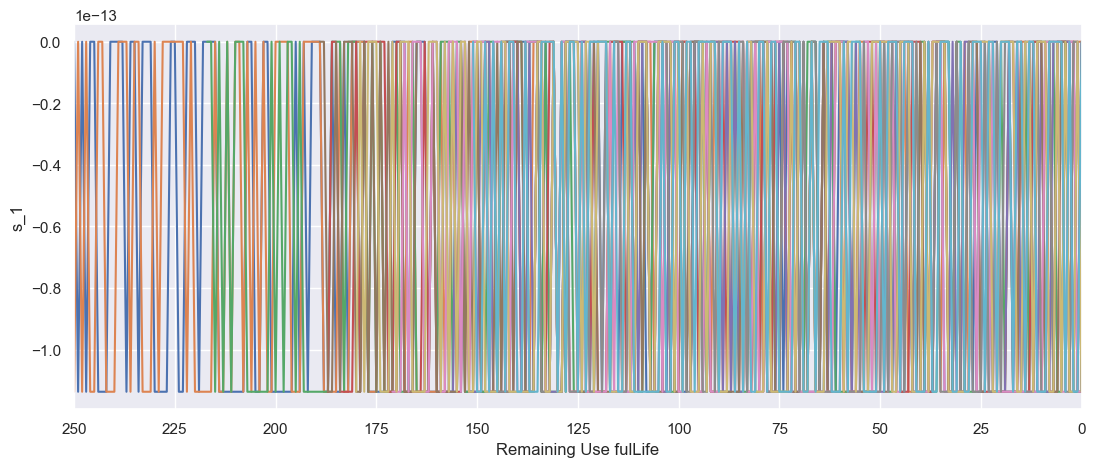

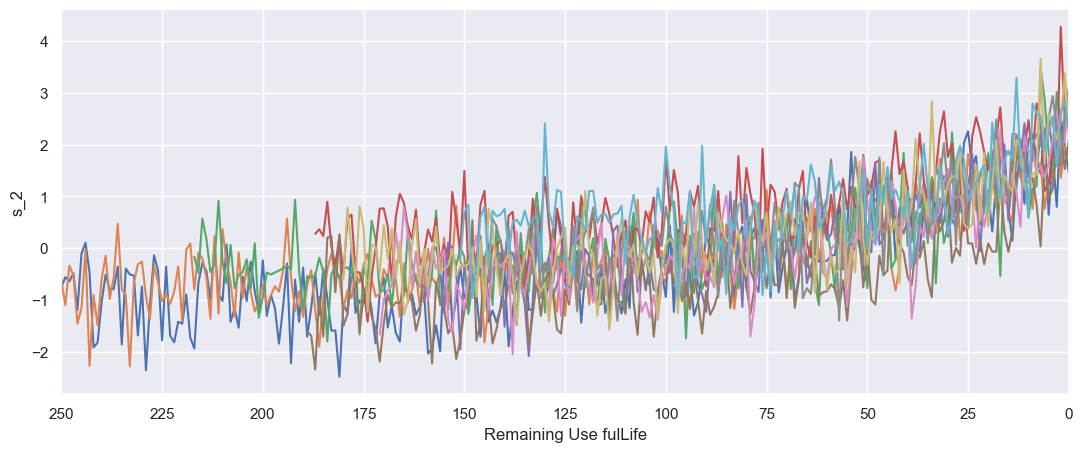

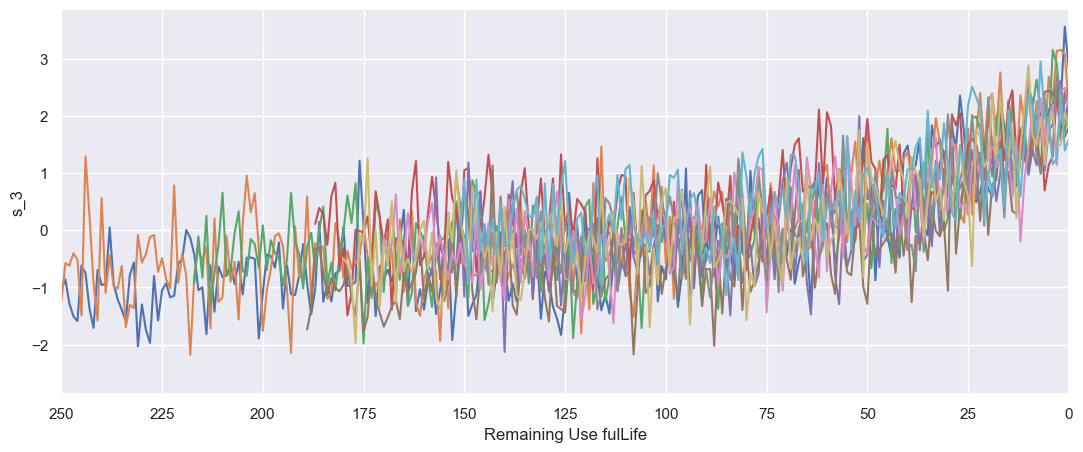

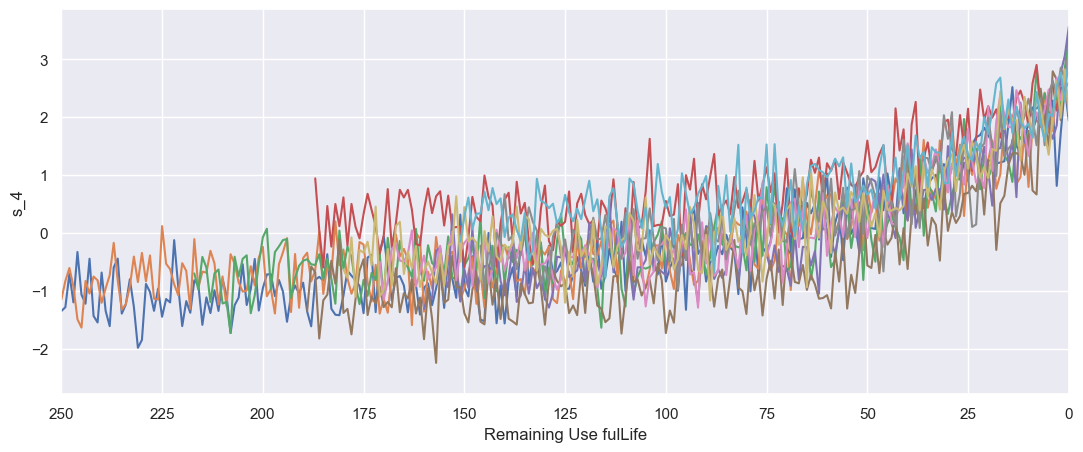

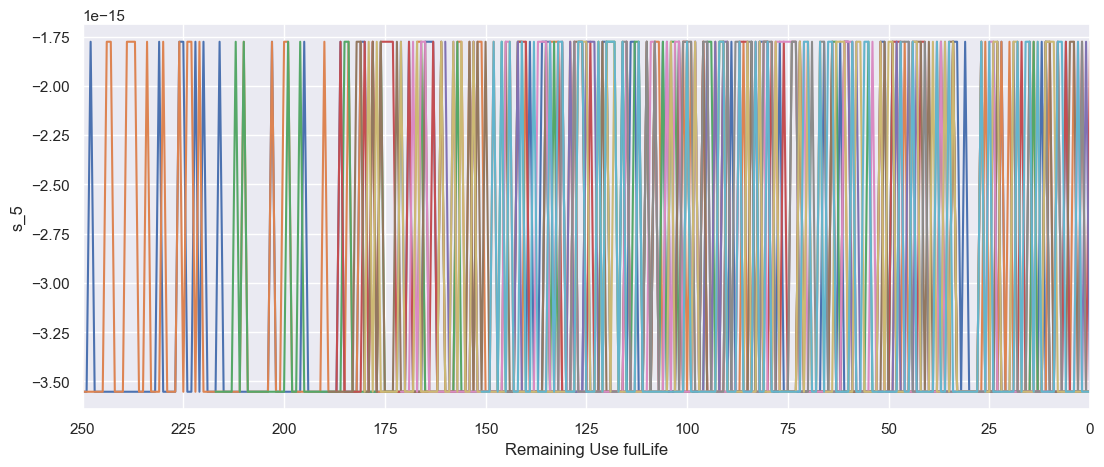

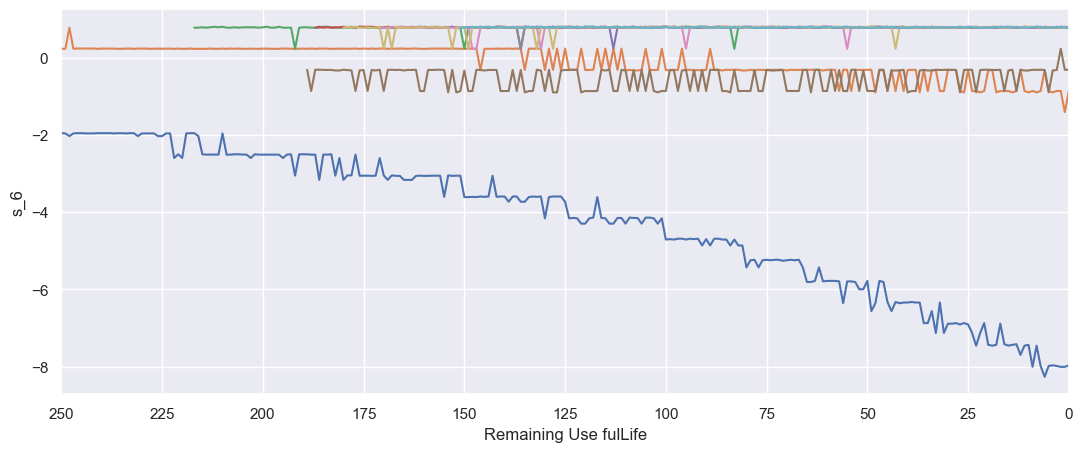

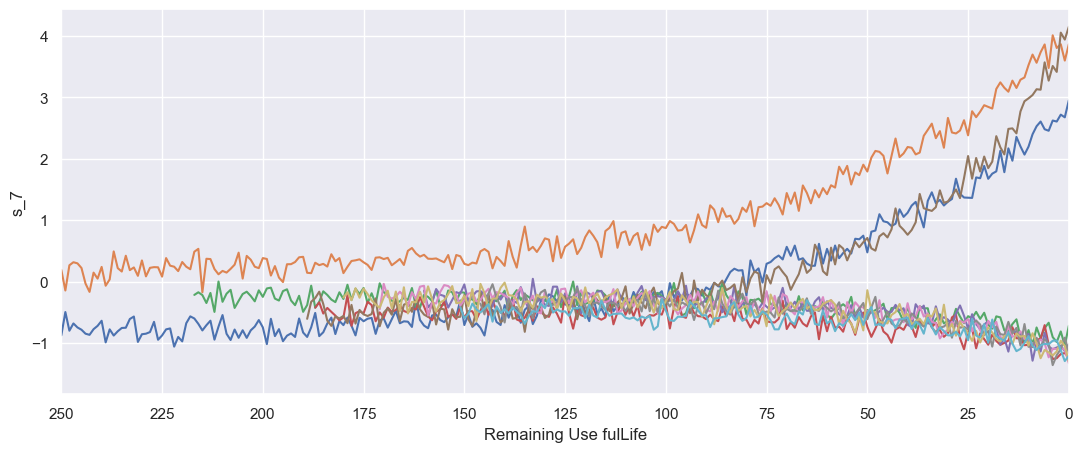

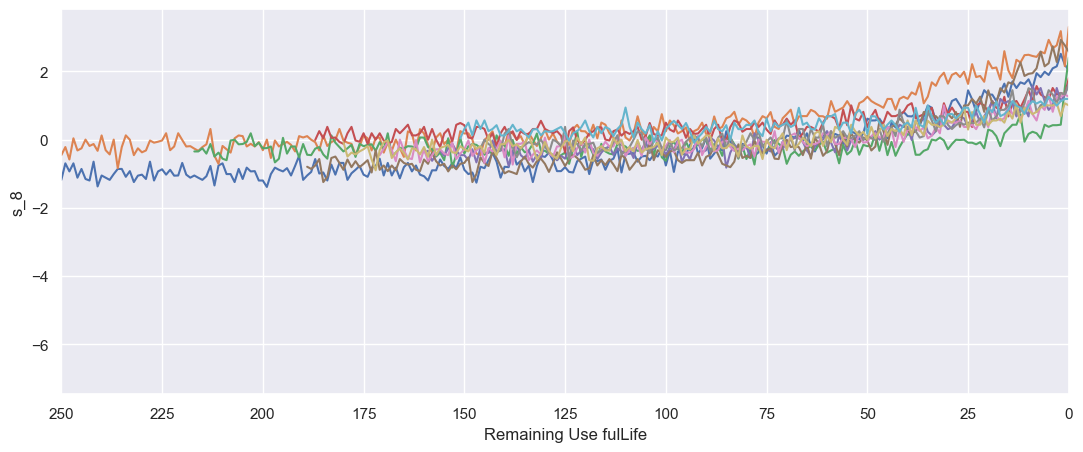

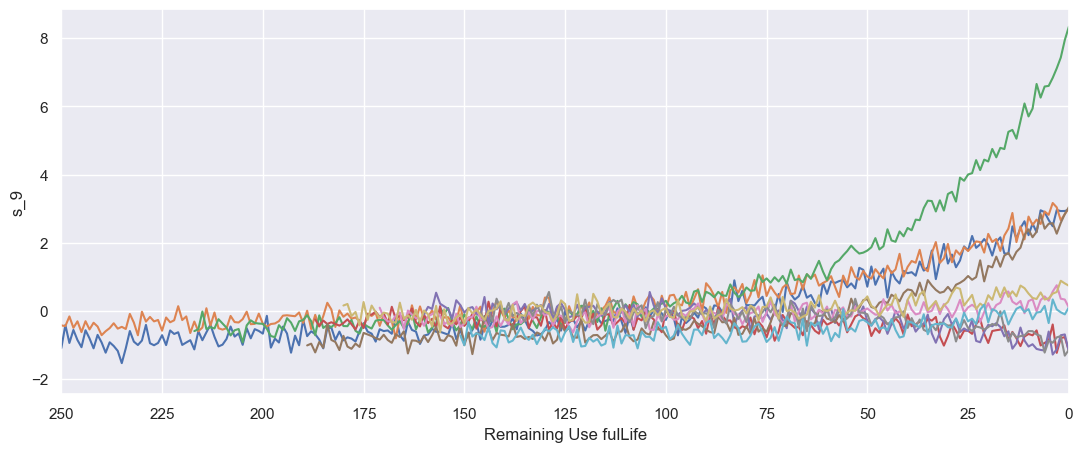

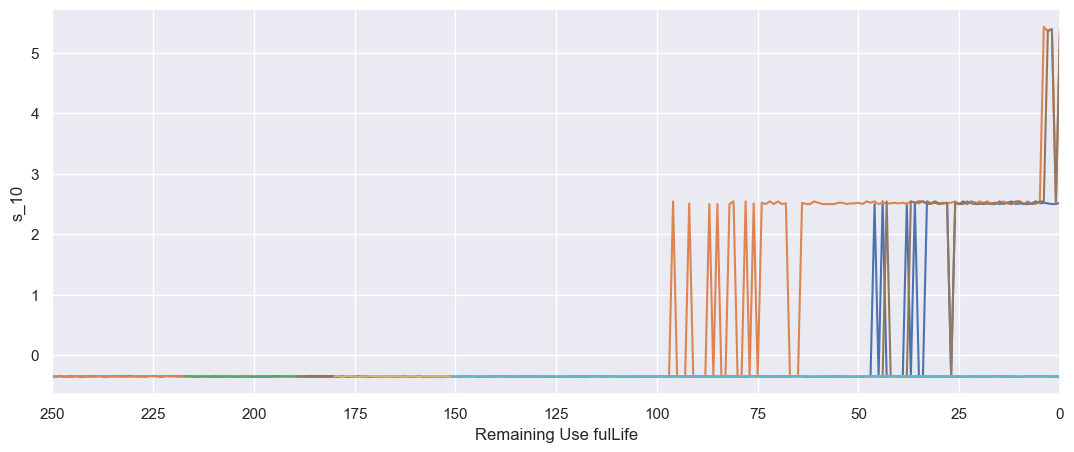

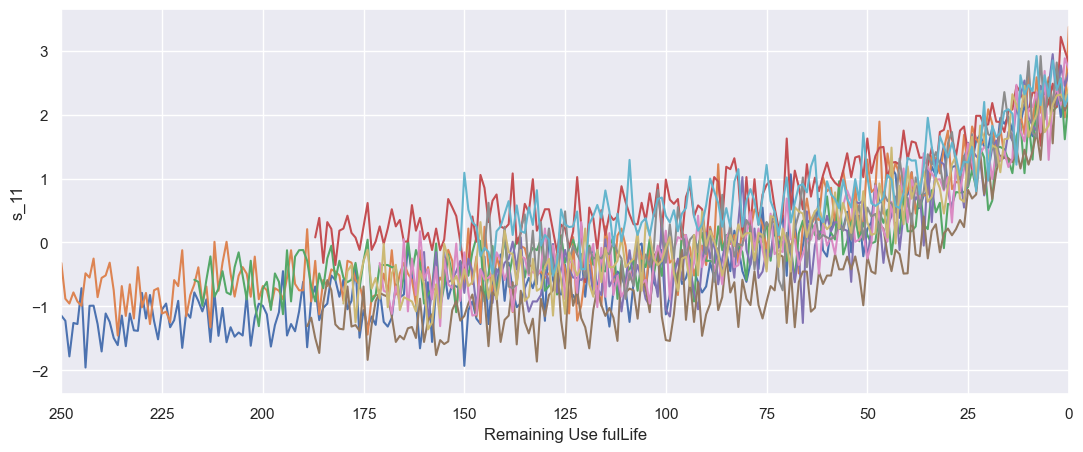

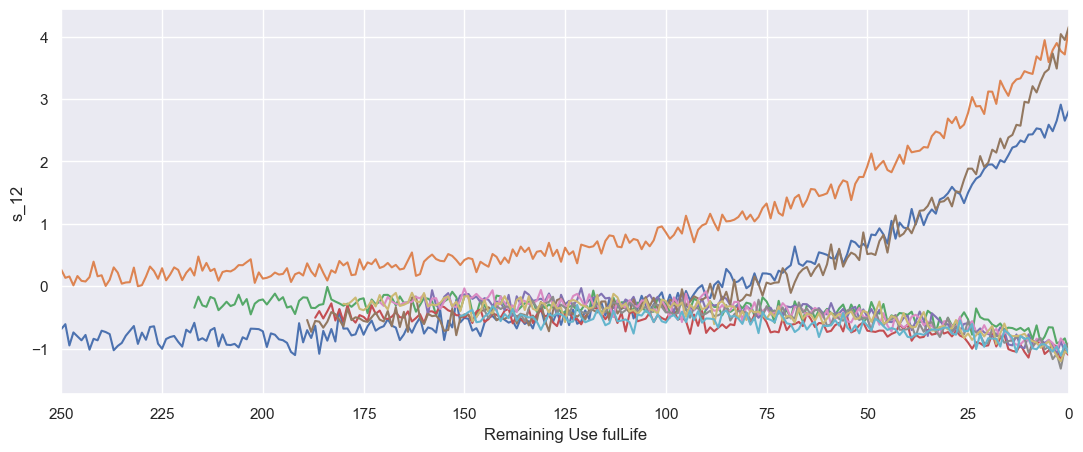

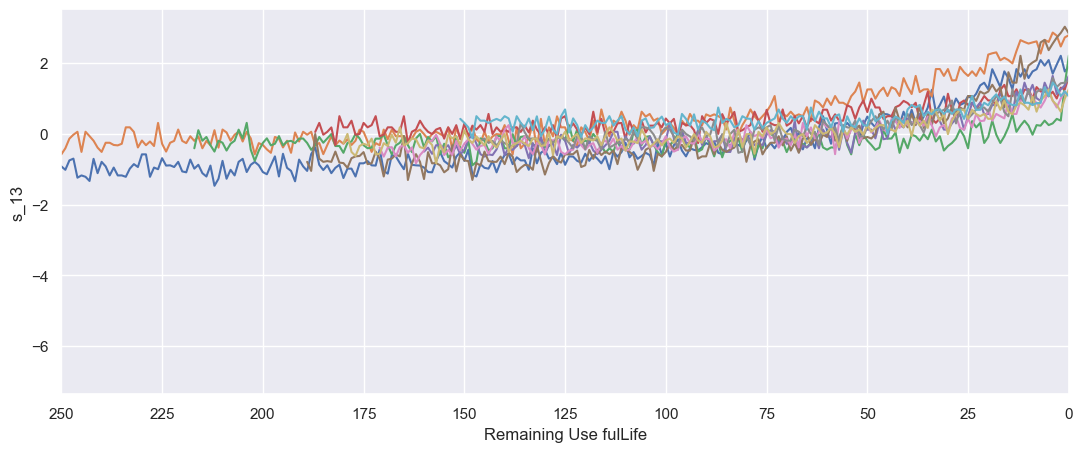

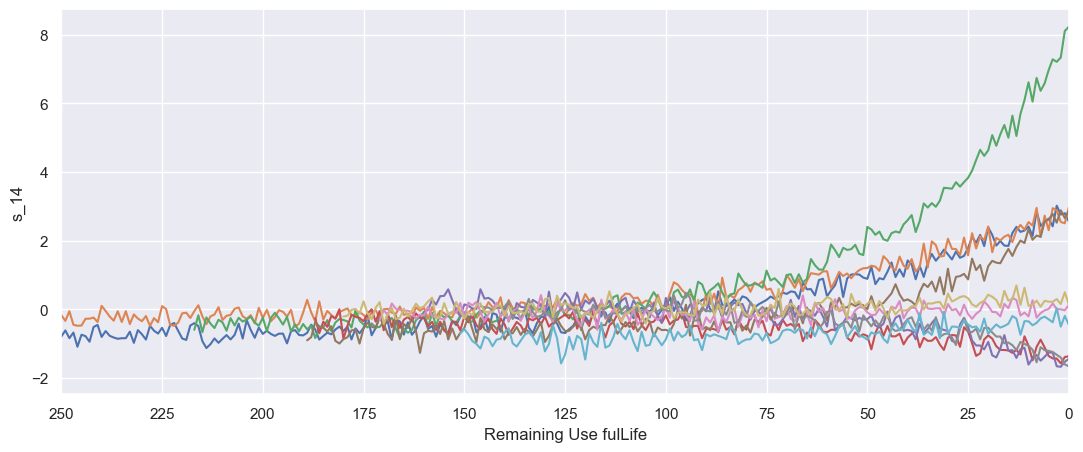

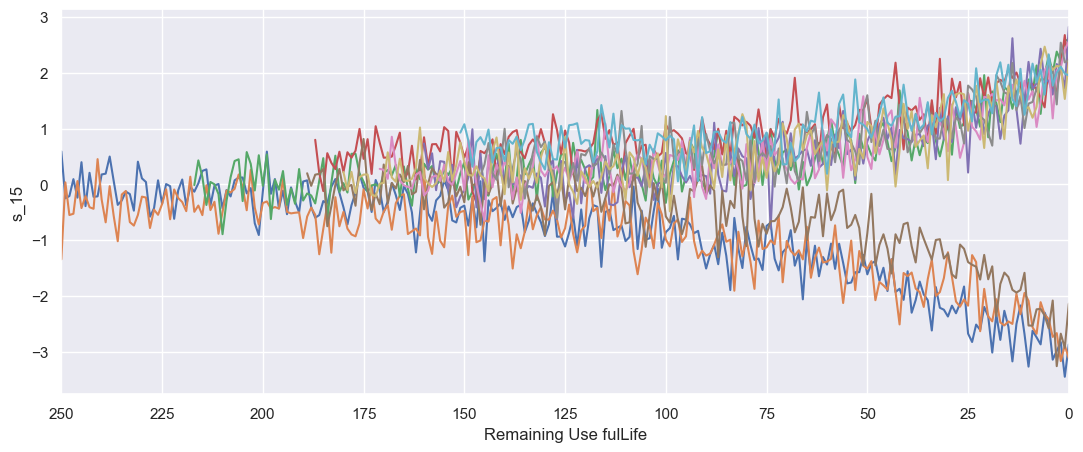

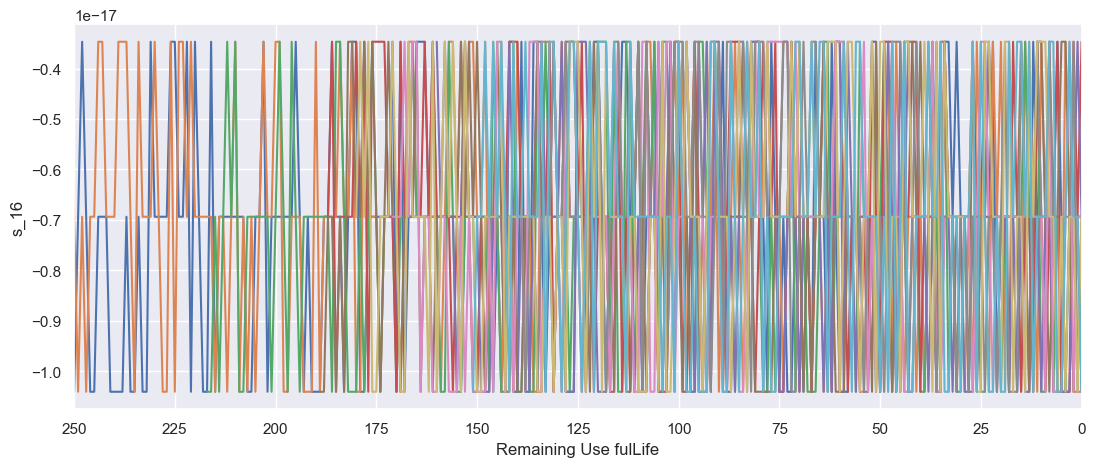

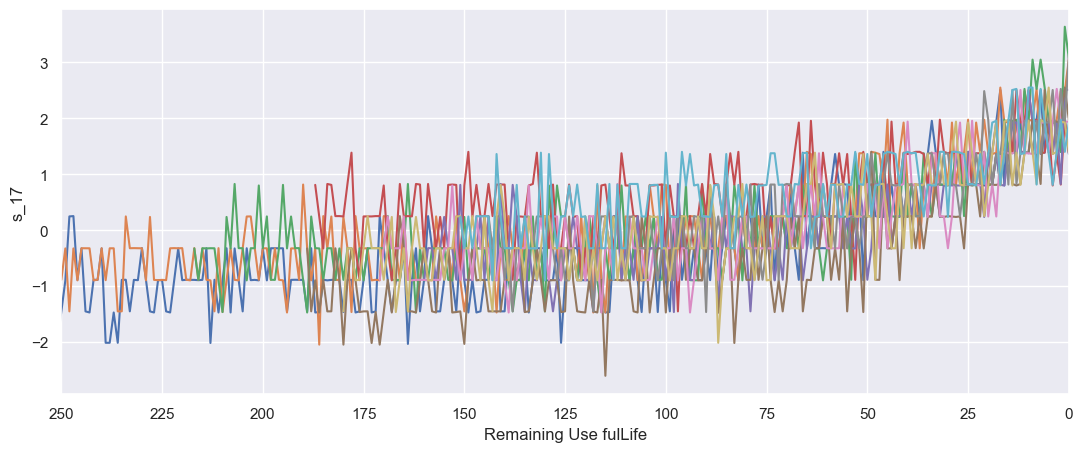

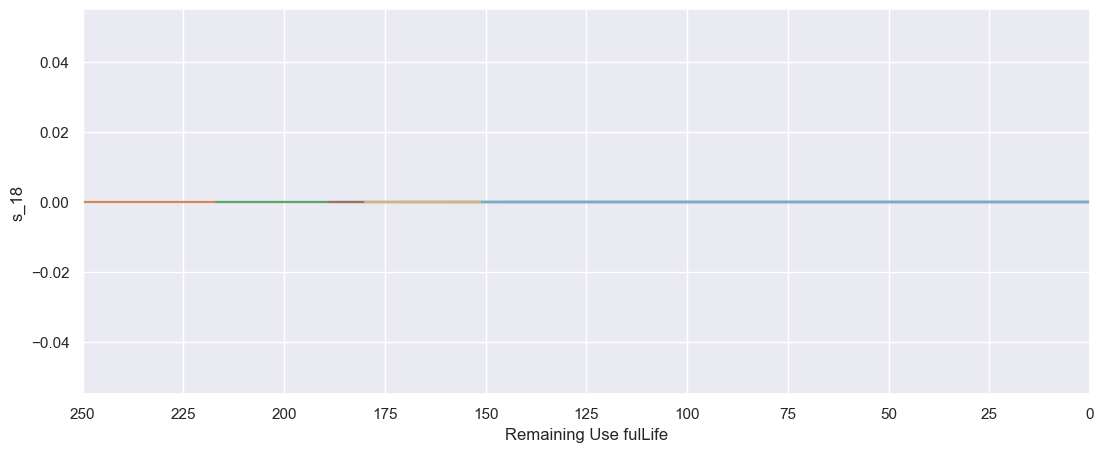

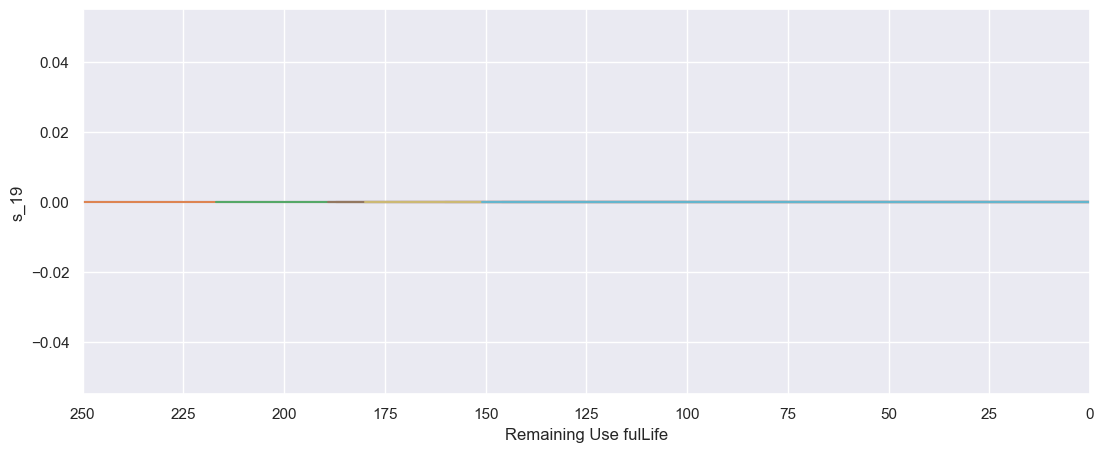

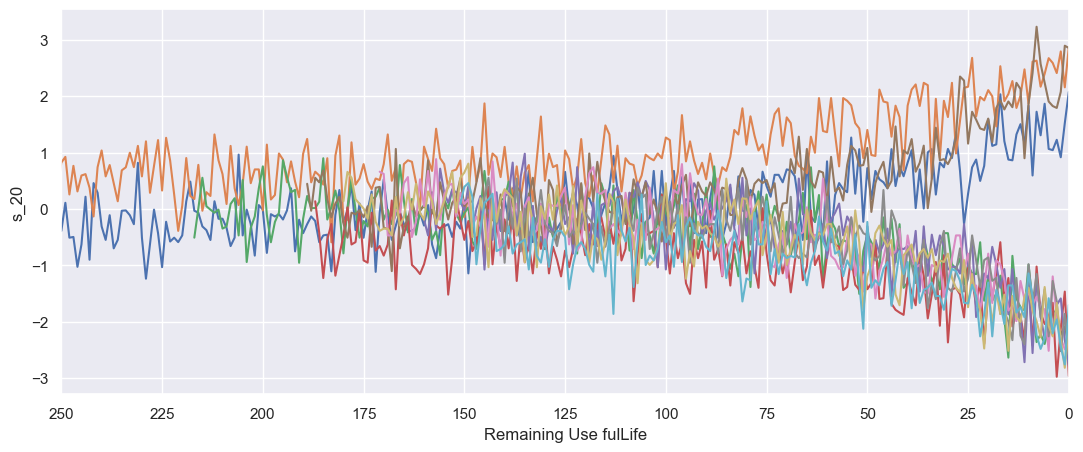

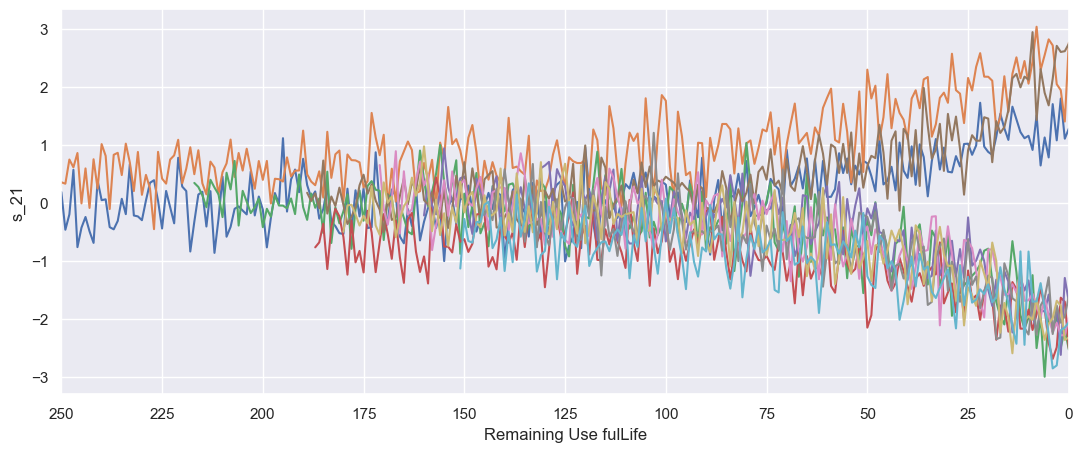

In [9]:
# before we start plotting, lets implement the condition specific scaling
def add_operating_condition(df):
    df_op_cond = df.copy()

    df_op_cond['setting_1'] = df_op_cond['setting_1'].round()
    df_op_cond['setting_2'] = df_op_cond['setting_2'].round(decimals=2)

    # converting settings to string and concatanating makes the operating condition into a categorical variable
    df_op_cond['op_cond'] = df_op_cond['setting_1'].astype(str) + '_' + \
                        df_op_cond['setting_2'].astype(str) + '_' + \
                        df_op_cond['setting_3'].astype(str)

    return df_op_cond

def condition_scaler(df_train, df_test, sensor_names):
    # apply operating condition specific scaling
    scaler = StandardScaler()
    for condition in df_train['op_cond'].unique():
        scaler.fit(df_train.loc[df_train['op_cond']==condition, sensor_names])
        df_train.loc[df_train['op_cond']==condition, sensor_names] = scaler.transform(df_train.loc[df_train['op_cond']==condition, sensor_names])
        df_test.loc[df_test['op_cond']==condition, sensor_names] = scaler.transform(df_test.loc[df_test['op_cond']==condition, sensor_names])
    return df_train, df_test
X_train_condition = add_operating_condition(train)
X_test_condition = add_operating_condition(X_test)

X_train_condition_scaled, X_test_condition_scaled = condition_scaler(X_train_condition, X_test_condition, sensor_names)
def plot_signal(df, signal_name, unit_nr=None):
    plt.figure(figsize=(13,5))

    if unit_nr:
        plt.plot('RUL', signal_name,
                data=df[df['unit_nr']==unit_nr])
    else:
        for i in train['unit_nr'].unique():
            if (i % 10 == 0):  # only ploting every 10th unit_nr
                plt.plot('RUL', signal_name,
                         data=df[df['unit_nr']==i])
    plt.xlim(250, 0)  # reverse the x-axis so RUL counts down to zero
    plt.xticks(np.arange(0, 275, 25))
    plt.ylabel(signal_name)
    plt.xlabel('Remaining Use fulLife')
    plt.show()
for sensor in sensor_names:
    plot_signal(X_train_condition_scaled, sensor)


In [10]:
remaining_sensors = ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9',
       's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
drop_sensors = [element for element in sensor_names if element not in remaining_sensors]

In [11]:
def exponential_smoothing(df, sensors, n_samples, alpha=0.4):
    df = df.copy()
    # first, take the exponential weighted mean
    df[sensors] = df.groupby('unit_nr')[sensors].apply(lambda x: x.ewm(alpha=alpha).mean())

    # second, drop first n_samples of each unit_nr to reduce filter delay
    def create_mask(data, samples):
        result = np.ones_like(data)
        result[0:samples] = 0
        return result

    mask = df.groupby('unit_nr')['unit_nr'].transform(create_mask, samples=n_samples).astype(bool)
    df = df[mask]

    return df
gss = GroupShuffleSplit(n_splits=1, train_size=0.80, random_state=42)  # eventhough we set np and tf seeds, gss requires its own seed

def train_val_group_split(X, y, gss, groups, print_groups=True):

    for idx_train, idx_val in gss.split(X, y, groups=groups):
        if print_groups:
            print('train_split_engines', train.iloc[idx_train]['unit_nr'].unique())
            print('validate_split_engines', train.iloc[idx_val]['unit_nr'].unique(), '\n')

        X_train_split = X.iloc[idx_train].copy()
        y_train_split = y.iloc[idx_train].copy()
        X_val_split = X.iloc[idx_val].copy()
        y_val_split = y.iloc[idx_val].copy()
    return X_train_split, y_train_split, X_val_split, y_val_split

In [12]:
d = {'unit_nr': [1]*5 + [2]*5,
     'X': [10., 10.2, 10.4, 10.6, 10.8, 20., 20.2, 20.4, 20.6, 20.8],
     'y': [1.4, 1.4, 1.3, 1.2, 1.1, 2.4, 2.4, 2.3, 2.2, 2.1]}
example_df = pd.DataFrame(data=d)
example_df

,unit_nr,X,y
0,1,10.0,1.4
1,1,10.2,1.4
2,1,10.4,1.3
3,1,10.6,1.2
4,1,10.8,1.1
5,2,20.0,2.4
6,2,20.2,2.4
7,2,20.4,2.3
8,2,20.6,2.2
9,2,20.8,2.1


In [13]:
def gen_train_data(df, sequence_length, columns):
    data = df[columns].values
    num_elements = data.shape[0]

    # -1 and +1 because of Python indexing
    for start, stop in zip(range(0, num_elements-(sequence_length-1)), range(sequence_length, num_elements+1)):
        yield data[start:stop, :]
gen = gen_train_data(example_df[example_df['unit_nr']==1], sequence_length=4, columns=['X'])
list(gen)

[array([[10. ],
        [10.2],
        [10.4],
        [10.6]]),
 array([[10.2],
        [10.4],
        [10.6],
        [10.8]])]

In [14]:
def gen_data_wrapper(df, sequence_length, columns, unit_nrs=np.array([])):
    if unit_nrs.size <= 0:
        unit_nrs = df['unit_nr'].unique()

    data_gen = (list(gen_train_data(df[df['unit_nr']==unit_nr], sequence_length, columns))
               for unit_nr in unit_nrs)
    data_array = np.concatenate(list(data_gen)).astype(np.float32)
    return data_array
data_array = gen_data_wrapper(example_df, sequence_length=4, columns=['X'])
data_array

array([[[10. ],
        [10.2],
        [10.4],
        [10.6]],

       [[10.2],
        [10.4],
        [10.6],
        [10.8]],

       [[20. ],
        [20.2],
        [20.4],
        [20.6]],

       [[20.2],
        [20.4],
        [20.6],
        [20.8]]], dtype=float32)

In [15]:
def gen_labels(df, sequence_length, label):
    data_matrix = df[label].values
    num_elements = data_matrix.shape[0]

    # -1 because I want to predict the rul of that last row in the sequence, not the next row
    return data_matrix[sequence_length-1:num_elements, :]

def gen_label_wrapper(df, sequence_length, label, unit_nrs=np.array([])):
    if unit_nrs.size <= 0:
        unit_nrs = df['unit_nr'].unique()

    label_gen = [gen_labels(df[df['unit_nr']==unit_nr], sequence_length, label)
                for unit_nr in unit_nrs]
    label_array = np.concatenate(label_gen).astype(np.float32)
    return label_array
label = gen_labels(example_df[example_df['unit_nr']==1], sequence_length=4, label=['y'])
label

label_array = gen_label_wrapper(example_df, sequence_length=4, label=['y'])
label_array

array([[1.2],
       [1.1],
       [2.2],
       [2.1]], dtype=float32)

In [16]:
def gen_test_data(df, sequence_length, columns, mask_value):
    if df.shape[0] < sequence_length:
        data_matrix = np.full(shape=(sequence_length, len(columns)), fill_value=mask_value) # pad
        idx = data_matrix.shape[0] - df.shape[0]
        data_matrix[idx:,:] = df[columns].values  # fill with available data
    else:
        data_matrix = df[columns].values

    # specifically yield the last possible sequence
    stop = num_elements = data_matrix.shape[0]
    start = stop - sequence_length
    for i in list(range(1)):
        yield data_matrix[start:stop, :]
# notice the masked value I passed is a float,
# it should be the same datatype as the data you're working with
gen = (list(gen_test_data(example_df[example_df['unit_nr']==unit_nr], sequence_length=6, columns=['X'], mask_value=-99.))
           for unit_nr in example_df['unit_nr'].unique())
next(gen)

[array([[-99. ],
        [ 10. ],
        [ 10.2],
        [ 10.4],
        [ 10.6],
        [ 10.8]])]

In [17]:
sequence_length = 20
num_features =  14
train['RUL'].clip(upper=125, inplace=True)

X_train_interim = add_operating_condition(train.drop(drop_sensors, axis=1))
X_test_interim = add_operating_condition(test.drop(drop_sensors, axis=1))

X_train_interim, X_test_interim = condition_scaler(X_train_interim, X_test_interim, remaining_sensors)

X_train_interim = exponential_smoothing(X_train_interim, remaining_sensors, 0, 0.4)
X_test_interim = exponential_smoothing(X_test_interim, remaining_sensors, 0, 0.4)

# train-val split
gss = GroupShuffleSplit(n_splits=1, train_size=0.80, random_state=42)
for train_unit, val_unit in gss.split(X_train_interim['unit_nr'].unique(), groups=X_train_interim['unit_nr'].unique()):
    train_unit = X_train_interim['unit_nr'].unique()[train_unit]  # gss returns indexes and index starts at 1
    val_unit = X_train_interim['unit_nr'].unique()[val_unit]

    train_split_array = gen_data_wrapper(X_train_interim, sequence_length, remaining_sensors, train_unit)
    train_split_label = gen_label_wrapper(X_train_interim, sequence_length, ['RUL'], train_unit)

    val_split_array = gen_data_wrapper(X_train_interim, sequence_length, remaining_sensors, val_unit)
    val_split_label = gen_label_wrapper(X_train_interim, sequence_length, ['RUL'], val_unit)

# create sequences train, test
train_array = gen_data_wrapper(X_train_interim, sequence_length, remaining_sensors)
label_array = gen_label_wrapper(X_train_interim, sequence_length, ['RUL'])

test_gen = (list(gen_test_data(X_test_interim[X_test_interim['unit_nr']==unit_nr], sequence_length, remaining_sensors, -99.))
           for unit_nr in X_test_interim['unit_nr'].unique())
test_array = np.concatenate(list(test_gen)).astype(np.float32)
input_shape=(sequence_length, train_array.shape[2])
# Define input branches
input_cnn = Input(shape=(sequence_length, num_features))
input_lstm = Input(shape=(sequence_length, num_features))

# CNN branch
cnn_branch = Masking(mask_value=-99.)(input_cnn)
cnn_branch = Conv1D(128, kernel_size=3, padding="same", activation="relu")(cnn_branch)
cnn_branch = MaxPooling1D(pool_size=2, padding='same')(cnn_branch)
cnn_branch = Flatten()(cnn_branch)
cnn_branch = Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01))(cnn_branch)
cnn_branch = Dropout(0.2)(cnn_branch)

# LSTM branch
lstm_branch = Masking(mask_value=-99.)(input_lstm)
lstm_branch = LSTM(units=128, return_sequences=True)(lstm_branch)
lstm_branch = LSTM(units=128, return_sequences=False, activation='tanh')(lstm_branch)
lstm_branch = Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01))(lstm_branch)
lstm_branch = Dropout(0.2)(lstm_branch)

# Concatenate the outputs of the two branches
merged = Concatenate()([cnn_branch, lstm_branch])

# Additional layers
merged = Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01))(merged)
merged = Dropout(0.2)(merged)

# Neural Network layer
output = Dense(1, activation='linear')(merged)

# Create the model
model = Model(inputs=[input_cnn, input_lstm], outputs=output)

# Define optimizer and learning rate
optimizer = Adam(learning_rate=0.001)

# Compile the model
model.compile(loss='mean_squared_error', optimizer=optimizer)

# Set up callbacks
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=15)  # Increased patience
mc = ModelCheckpoint('best_deeper_model.h5', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

# Implement learning rate scheduling
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.00001, verbose=1)

# Define hyperparameter search space for optimizer
def build_model(hp):
    optimizer_choice = hp.Choice('optimizer', values=['adam', 'rmsprop'])
    learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5)
    units = hp.Int('units', min_value=64, max_value=256, step=64)

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    # CNN branch
    cnn_branch = Masking(mask_value=-99.)(input_cnn)
    cnn_branch = Conv1D(128, kernel_size=3, padding="same", activation="relu")(cnn_branch)
    cnn_branch = MaxPooling1D(pool_size=2, padding='same')(cnn_branch)
    cnn_branch = Flatten()(cnn_branch)
    cnn_branch = Dense(128, activation='relu')(cnn_branch)
    cnn_branch = Dropout(0.2)(cnn_branch)

    # LSTM branch
    lstm_branch = Masking(mask_value=-99.)(input_lstm)
    lstm_branch = LSTM(units=128, return_sequences=True)(lstm_branch)
    lstm_branch = LSTM(units=128, return_sequences=False, activation='tanh')(lstm_branch)
    lstm_branch = Dense(128, activation='relu')(lstm_branch)
    lstm_branch = Dropout(0.2)(lstm_branch)

    # Concatenate the outputs of the two branches
    merged = Concatenate()([cnn_branch, lstm_branch])

    # Additional layers
    merged = Dense(units, activation='relu', kernel_regularizer=regularizers.l2(0.01))(merged)
    merged = Dropout(dropout_rate)(merged)

    # Neural Network layer
    output = Dense(1, activation='linear')(merged)

    # Create the model
    model = Model(inputs=[input_cnn, input_lstm], outputs=output)

    # Compile the model with the selected optimizer
    model.compile(loss='mean_squared_error', optimizer=optimizer)

    return model

# Instantiate the tuner
tuner = Hyperband(
    build_model,
    objective='val_loss',
    max_epochs=30,  # Maximum number of epochs per trial
    factor=3,  # Reduction factor for halving the number of configurations
    directory='hyperparameter_tuning',
    project_name='my_tuning_project'
)

# Perform hyperparameter search
tuner.search([train_split_array, train_split_array], train_split_label,
             validation_data=([val_split_array, val_split_array], val_split_label),
             epochs=30,
             batch_size=32,
             callbacks=[es, mc, reduce_lr])

# Get the best model
best_model = tuner.get_best_models(num_models=1)[0]

# Train the best model for more epochs (if desired)
best_history = best_model.fit([train_split_array, train_split_array], train_split_label,
                             validation_data=([val_split_array, val_split_array], val_split_label),
                             epochs=50,
                             batch_size=32,
                             callbacks=[es, mc, reduce_lr])

Trial 90 Complete [00h 23m 15s]
val_loss: 197.51930236816406

Best val_loss So Far: 158.8349609375
Total elapsed time: 06h 05m 57s
Epoch 1/50
578/578 [==============================] - ETA: 0s - loss: 163.4978
Epoch 1: val_loss improved from inf to 214.40851, saving model to best_deeper_model.h5
578/578 [==============================] - 61s 95ms/step - loss: 163.4978 - val_loss: 214.4085 - lr: 0.0010
Epoch 2/50
578/578 [==============================] - ETA: 0s - loss: 152.6080
Epoch 2: val_loss did not improve from 214.40851
578/578 [==============================] - 54s 93ms/step - loss: 152.6080 - val_loss: 216.4382 - lr: 0.0010
Epoch 3/50
578/578 [==============================] - ETA: 0s - loss: 146.4671
Epoch 3: val_loss improved from 214.40851 to 180.95566, saving model to best_deeper_model.h5
578/578 [==============================] - 54s 93ms/step - loss: 146.4671 - val_loss: 180.9557 - lr: 0.0010
Epoch 4/50
578/578 [==============================] - ETA: 0s - loss: 133.1966


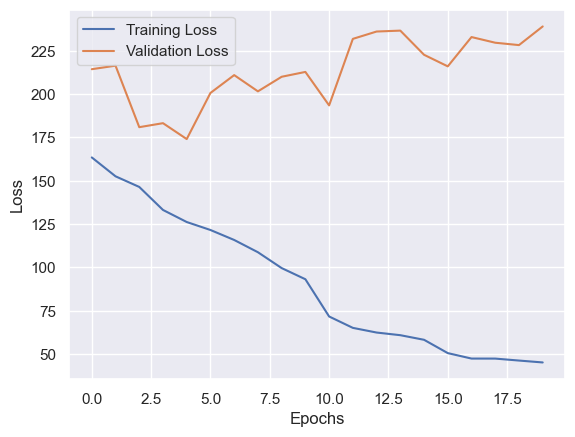

In [18]:
plt.plot(best_history.history['loss'], label='Training Loss')
plt.plot(best_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [19]:
y_hat_train = best_model.predict([train_split_array, train_split_array])
y_hat_val = best_model.predict([val_split_array, val_split_array])
y_hat_test = best_model.predict([test_array, test_array])
evaluate(train_split_label, y_hat_train, 'train')
evaluate(val_split_label, y_hat_val, 'validation')
evaluate(y_test, y_hat_test, 'test')

4/4 [==============================] - 0s 24ms/step
train set RMSE:3.6773078441619873, R2:0.9919972331788317
validation set RMSE:15.422000885009766, R2:0.8617548367990112
test set RMSE:17.493018218360643, R2:0.821425002936572
